# Customer Churn Prediction
Проект посвящён прогнозированию оттока клиентов телекоммуникационной компании с помощью методов машинного обучения. Задача формулируется как бинарная классификация: необходимо оценить, уйдёт ли клиент (Churn = Yes) или останется (Churn = No).

**Цель проекта:** исследовать данные, подготовить признаки, сравнить базовые модели классификации, выбрать рабочий порог вероятности оттока и оценить итоговое качество на отложенной тестовой выборке.

**Основные этапы:** обзор данных, проверка качества, исследовательский анализ, предобработка, обучение и оценка моделей, сохранение модели и выводы.

>Перед запуском разместите файл WA_Fn-UseC_-Telco-Customer-Churn.csv в папке data/ в корне проекта. Ноутбук рассчитан на запуск из корневой папки проекта или из папки notebooks/.

## 1. Data Overview

На этом этапе загружаем датасет, изучаем структуру таблицы и смотрим на распределение целевой переменной.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

### 1.1. Loading the dataset

Определяем корневую папку проекта и загружаем CSV. Такой подход позволяет запускать ноутбук как из корня проекта, так и из папки notebooks/.

In [2]:
project_root = Path.cwd()
if not (project_root / "data").exists() and (project_root.parent / "data").exists():
    project_root = project_root.parent

data_path = project_root / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print("Корневая папка проекта:", project_root.resolve())
print("Путь к датасету:", data_path.resolve())

if not data_path.is_file():
    raise FileNotFoundError(
        f"Не найден файл {data_path}. Поместите CSV в папку data/ в корне проекта."
    )

df = pd.read_csv(data_path)
print("Данные загружены.")
print("Размер таблицы:", df.shape)
display(df.head())

Корневая папка проекта: D:\All projects\PycharmProjects\customer-churn-prediction
Путь к датасету: D:\All projects\PycharmProjects\customer-churn-prediction\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
Данные загружены.
Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2. Initial inspection
Проверяем типы столбцов, количество строк и первичное распределение целевой переменной. На этом этапе пропуски и типы данных ещё не исправляем.

In [3]:
print("Информация о таблице:")
df.info()

Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [4]:
print("Количество пропущенных значений до очистки:")
display(df.isna().sum().to_frame("Missing values").query("`Missing values` > 0"))

Количество пропущенных значений до очистки:


,Missing values


Распределение целевой переменной:


,Количество
Churn,
No,5174
Yes,1869


,"Доля, %"
Churn,
No,73.46
Yes,26.54


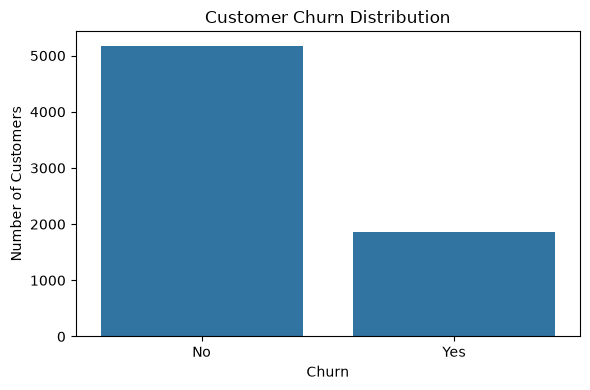

In [5]:
print("Распределение целевой переменной:")
display(df["Churn"].value_counts().to_frame("Количество"))
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("Доля, %"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 2. Data Quality Checks

На этом этапе проверяем качество данных: целевую переменную, дубликаты, типы данных, пустые строки и статистические характеристики числовых столбцов.


In [6]:
print("Уникальные значения Churn:")
print(df["Churn"].unique())

print("\nКоличество дубликатов строк:")
print(df.duplicated().sum())

print("\nТип данных TotalCharges:")
print(df["TotalCharges"].dtype)

# Подсчёт пустых строк в столбце TotalCharges
empty_total_charges = (
    df["TotalCharges"].astype(str).str.strip().eq("").sum()
)

print("\nКоличество пустых строк в TotalCharges:")
print(empty_total_charges)

print("\nСтатистика числовых столбцов:")
display(df.describe())

Уникальные значения Churn:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Количество дубликатов строк:
0

Тип данных TotalCharges:
str

Количество пустых строк в TotalCharges:
11

Статистика числовых столбцов:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 2.1. Investigating Empty TotalCharges

Проверяем пустые строки в TotalCharges и выясняем, связаны ли они с нулевым сроком обслуживания. Пустые строки не считаются пропусками NaN, пока их не преобразовали.

In [7]:
# Поиск строк с пустыми значениями в TotalCharges
empty_mask = df["TotalCharges"].astype(str).str.strip().eq("")

print("Количество строк с пустым TotalCharges:", empty_mask.sum())

print("\nРаспределение tenure для этих клиентов:")
print(df.loc[empty_mask, "tenure"].value_counts())

display(
    df.loc[empty_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
)

Количество строк с пустым TotalCharges: 11

Распределение tenure для этих клиентов:
tenure
0    11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### 2.2. Converting TotalCharges to a Numeric Format

Преобразуем TotalCharges в числовой тип. Пустые строки будут преобразованы в NaN, чтобы затем обработать их внутри конвейера предобработки. 

In [8]:
# Преобразование TotalCharges в числовой формат, пустые значения заменяются на NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("Тип данных TotalCharges:", df["TotalCharges"].dtype)
print("Количество пропущенных значений:", df["TotalCharges"].isna().sum())

display(
    df.loc[
        df["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

Тип данных TotalCharges: float64
Количество пропущенных значений: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [9]:
print("Уникальные customerID:", df["customerID"].is_unique)
print("Пропуски после преобразования:")
display(df.isna().sum().to_frame("Missing values").query("`Missing values` > 0"))

print("Число пустых TotalCharges после преобразования:", df["TotalCharges"].isna().sum())
print("Число строк с tenure = 0 и пропущенным TotalCharges:", ((df["tenure"] == 0) & df["TotalCharges"].isna()).sum())

Уникальные customerID: True
Пропуски после преобразования:


,Missing values
TotalCharges,11


Число пустых TotalCharges после преобразования: 11
Число строк с tenure = 0 и пропущенным TotalCharges: 11


## 3. Exploratory Data Analysis

Исследуем, как доля оттока связана с типом договора, сроком обслуживания и ежемесячными платежами. Наблюдаемые связи описывают данные, но сами по себе не доказывают причинно-следственную зависимость.

### 3.1. Contract Type and Churn Rate

Рассчитываем долю ушедших клиентов для каждого типа договора и сравниваем категории.

Доля оттока по типам договора:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn_binary, dtype: float64


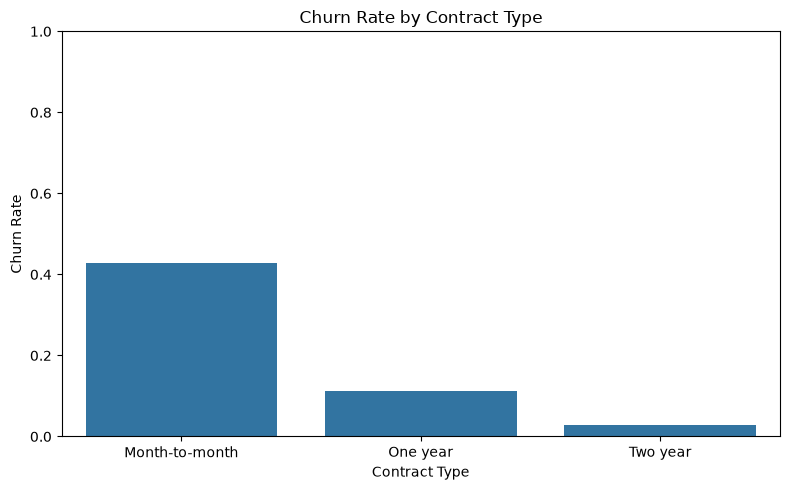

In [10]:
# Преобразуем целевую переменную Churn в числовой формат:
df["Churn_binary"] = df["Churn"].map({"No": 0, "Yes": 1})

# Рассчитываем долю ушедших клиентов для каждого типа договора
churn_by_contract = df.groupby("Contract")["Churn_binary"].mean()

# Выводим долю оттока в процентах
print("Доля оттока по типам договора:")
print((churn_by_contract * 100).round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

**Вывод:** в этих данных доля оттока выше среди клиентов с помесячным договором (42,71%) и ниже среди клиентов с двухлетним договором (2,83%). Это наблюдаемая связь, а не доказательство того, что тип договора сам по себе вызывает отток.

### 3.2. Customer Tenure and Churn

Сравниваем распределение срока обслуживания клиентов и долю оттока в зависимости от стажа.

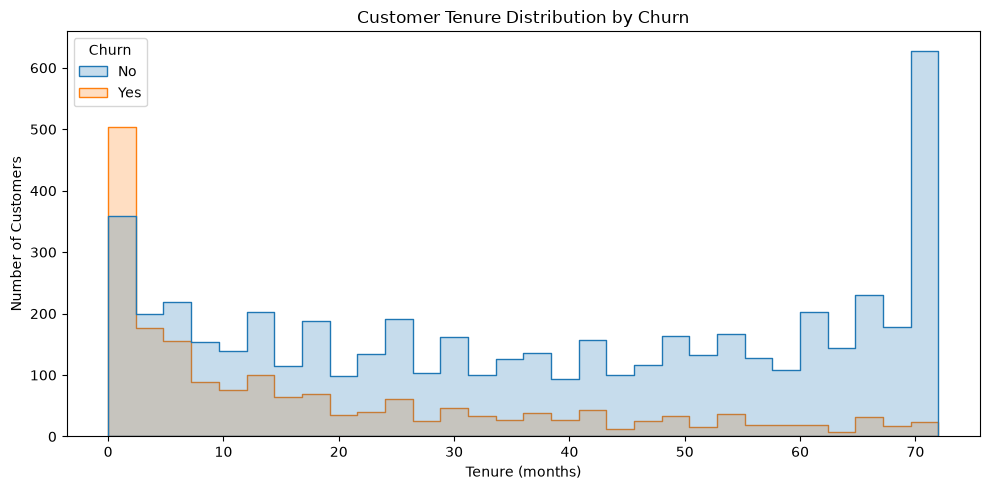

In [11]:
# Строим гистограмму срока обслуживания клиентов
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    element="step"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Гистограмма показывает распределение числа клиентов по сроку обслуживания в разрезе оттока. Поскольку значения объединены в интервалы (bins), по этому графику не следует делать точные выводы о количестве клиентов с конкретным значением tenure.

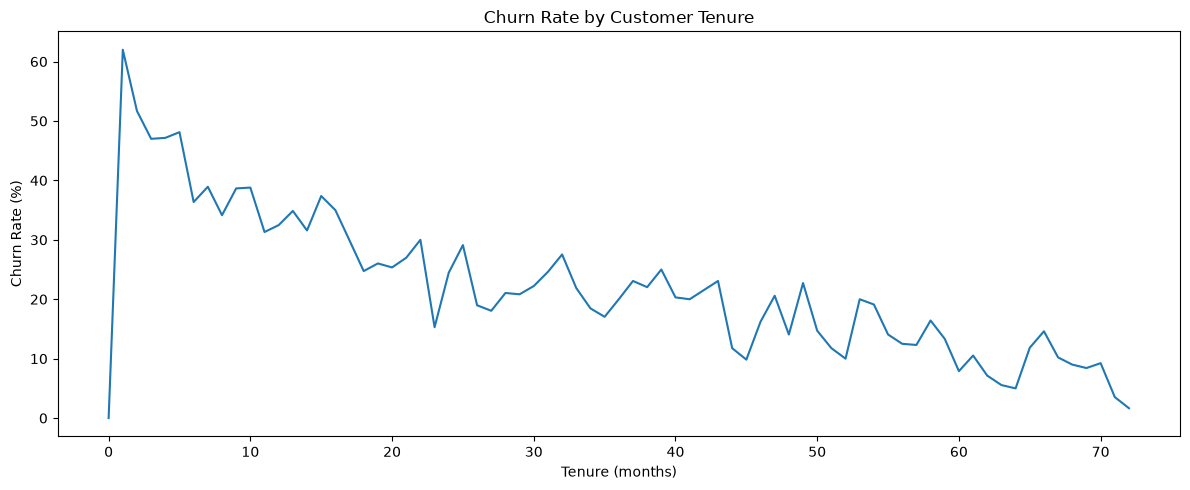

In [12]:
# Рассчитываем долю ушедших клиентов для каждого срока обслуживания
churn_by_tenure = (
    df.groupby("tenure")["Churn_binary"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

На графике доля оттока в целом выше при небольшом сроке обслуживания и снижается по мере увеличения стажа. Для отдельных значений стажа число наблюдений может быть небольшим, поэтому локальные колебания линии нужно интерпретировать осторожно. Практический вывод: ранний период обслуживания стоит дополнительно исследовать как возможное окно для мероприятий по удержанию клиентов.

### 3.3. Monthly Charges and Churn

Сравниваем распределение ежемесячных платежей у клиентов, которые ушли, и клиентов, которые остались. Гистограмма показывает число наблюдений, а не непосредственно вероятность оттока в каждом диапазоне платежей.

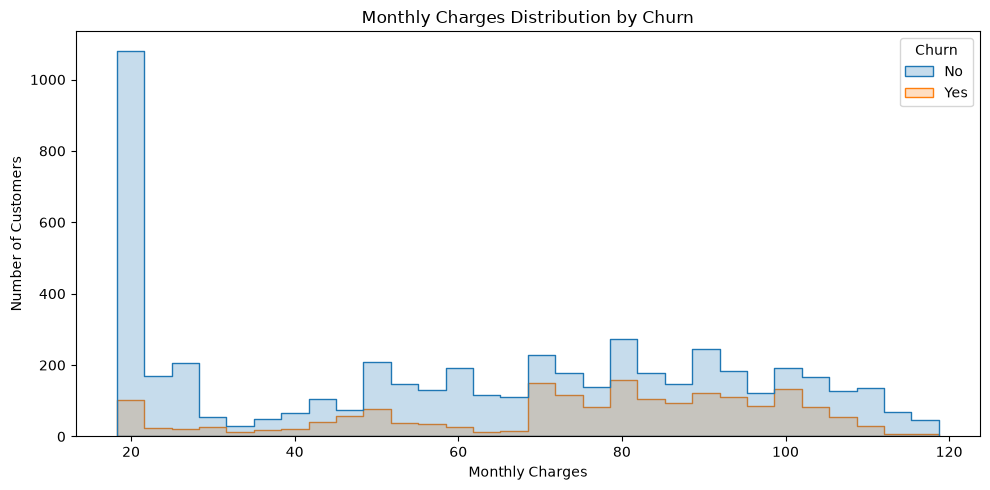

In [13]:
# Распределение ежемесячных платежей по группам оттока
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    multiple="layer",
    element="step"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

По гистограмме можно сравнить распределения MonthlyCharges в двух группах. Визуальное различие распределений само по себе не позволяет заключить, что в конкретном диапазоне платежей вероятность оттока выше. Для количественного сравнения доли оттока по диапазонам платежей потребуется отдельная группировка признака на интервалы.

### 3.4. EDA Summary
- В исследуемом датасете отток заметно различается между типами договоров: наиболее высокая доля наблюдается у клиентов с помесячными договорами.
- Доля оттока в целом выше у клиентов с небольшим стажем обслуживания.
- Распределения ежемесячных платежей у ушедших и оставшихся клиентов различаются, но для оценки доли оттока по диапазонам платежей нужен отдельный расчёт.
- Эти результаты используются как ориентиры для моделирования; они не доказывают причинно-следственные связи.

## 4. Data Preprocessing

### 4.1. Preparing Features and Splitting the Data

Отделяем целевую переменную от признаков и создаём обучающую и тестовую выборки. stratify=y сохраняет примерно одинаковую долю оттока в обеих выборках. Тестовая выборка предназначена для финальной оценки; подбор модели и порога будет выполняться на валидационной выборке внутри обучающей части.

In [14]:
# Разделяем целевую переменную и признаки
y = df["Churn_binary"]

X = df.drop(
    columns=["Churn", "Churn_binary", "customerID"]
)

# Разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Проверяем размеры выборок
print("Размеры выборок:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Проверяем долю оттока в каждой выборке
print("\nДоля оттока клиентов:")
print(f"Полная выборка: {y.mean() * 100:.2f}%")
print(f"Обучающая выборка: {y_train.mean() * 100:.2f}%")
print(f"Тестовая выборка: {y_test.mean() * 100:.2f}%")


Размеры выборок:
X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)

Доля оттока клиентов:
Полная выборка: 26.54%
Обучающая выборка: 26.54%
Тестовая выборка: 26.54%


### 4.2. Identifying Feature Types
Разделяем признаки на числовые и категориальные группы, чтобы применять к ним подходящие преобразования.

In [15]:
# Проверяем типы данных всех признаков
print("Типы данных столбцов:")
print(X_train.dtypes)

Типы данных столбцов:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [16]:
# Получаем список числовых признаков
numeric_features = list(
    X_train.select_dtypes(include="number").columns
)

# Получаем список категориальных признаков
categorical_features = list(
    X_train.select_dtypes(include=["str", "object", "category", "bool"]).columns
)

# Проверяем количество признаков
print("Количество числовых признаков:", len(numeric_features))
print("Количество категориальных признаков:", len(categorical_features))

Количество числовых признаков: 4
Количество категориальных признаков: 15


In [17]:
# Выводим названия признаков каждой группы
print("\nЧисловые признаки:")
print(numeric_features)

print("\nКатегориальные признаки:")
print(categorical_features)


Числовые признаки:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [18]:
# Проверяем отсутствие повторов и полноту разделения
all_features = numeric_features + categorical_features

print("Проверка разделения:")
print("Всего признаков в X_train:", X_train.shape[1])
print("Всего признаков в двух группах:", len(all_features))
print("Повторяющихся признаков нет:", len(all_features) == len(set(all_features)))
print("Все признаки учтены:", set(all_features) == set(X_train.columns))

Проверка разделения:
Всего признаков в X_train: 19
Всего признаков в двух группах: 19
Повторяющихся признаков нет: True
Все признаки учтены: True


### 4.3. Handling Missing Values
Числовые пропуски заполняем медианой, а категориальные — наиболее частым значением. Значения статистик будут вычисляться при обучении конвейера только на тренировочных данных.

In [19]:
# Проверяем количество пропущенных значений в каждом столбце
missing_values = X_train.isna().sum()

print("Количество пропущенных значений по столбцам:")
print(missing_values[missing_values > 0])

Количество пропущенных значений по столбцам:
TotalCharges    8
dtype: int64


In [20]:
# Создаём обработчик пропусков для числовых признаков
numeric_imputer = SimpleImputer(
    strategy="median"
)

# Создаём обработчик пропусков для категориальных признаков
categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

# Проверяем созданные обработчики
print("\nОбработчик числовых признаков:")
print(numeric_imputer)

print("\nОбработчик категориальных признаков:")
print(categorical_imputer)


Обработчик числовых признаков:
SimpleImputer(strategy='median')

Обработчик категориальных признаков:
SimpleImputer(strategy='most_frequent')


### 4.4. Encoding and Scaling Features
Категориальные признаки кодируем методом One-Hot Encoding. Числовые признаки масштабируем с помощью StandardScaler, что особенно полезно для логистической регрессии.

In [21]:
# Создаём обработчик категориальных признаков
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

# Создаём обработчик числовых признаков
scaler = StandardScaler()

# Проверяем создание обработчиков
print("Кодировщик категориальных признаков:")
print(encoder)

print("\nМасштабировщик числовых признаков:")
print(scaler)

Кодировщик категориальных признаков:
OneHotEncoder(handle_unknown='ignore')

Масштабировщик числовых признаков:
StandardScaler()


### 4.5. Creating the Preprocessing Pipeline
Объединяем обработку числовых и категориальных признаков в ColumnTransformer, затем помещаем его в Pipeline. Для каждой модели ниже будет использоваться отдельная копия препроцессора.

In [22]:
# Создаём конвейер обработки числовых признаков
numeric_transformer = Pipeline(steps=[
    ("imputer", numeric_imputer),
    ("scaler", scaler)
])

# Создаём конвейер обработки категориальных признаков
categorical_transformer = Pipeline(steps=[
    ("imputer", categorical_imputer),
    ("encoder", encoder)
])

# Объединяем обработчики для разных групп признаков
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Создаём общий конвейер предобработки
preprocessing_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

print("Числовой конвейер:")
print(numeric_transformer)

print("\nКатегориальный конвейер:")
print(categorical_transformer)

print("\nОбщий конвейер предобработки:")
print(preprocessing_pipeline)

Числовой конвейер:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Категориальный конвейер:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])

Общий конвейер предобработки:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                       

### 4.6. Validating the Preprocessing Pipeline
Проверяем, что преобразование сохраняет количество объектов и удаляет пропуски. Эти преобразованные матрицы используются только для диагностики; при обучении моделей обработка выполняется внутри их собственных конвейеров.

In [23]:
from scipy.sparse import issparse

# Сохраняем целевые переменные для последующей проверки
y_train_before = y_train.copy()
y_test_before = y_test.copy()

In [24]:
# Обучаем обработчик только на обучающей выборке
preprocessing_pipeline.fit(X_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colum

In [25]:
# Преобразуем обучающую и тестовую выборки
X_train_processed = preprocessing_pipeline.transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

# Проверяем размеры преобразованных данных
print("Размеры преобразованных данных:")
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

Размеры преобразованных данных:
X_train_processed: (5634, 45)
X_test_processed: (1409, 45)


In [26]:
# Проверяем количество строк
print("Проверка количества строк:")
print("Обучающая выборка:", X_train_processed.shape[0])
print("Тестовая выборка:", X_test_processed.shape[0])

Проверка количества строк:
Обучающая выборка: 5634
Тестовая выборка: 1409


In [27]:
# Проверяем наличие пропусков
print("Проверка пропущенных значений:")
print(
    "Пропуски в обучающей выборке:",
    np.isnan(X_train_processed.data).sum()
    if issparse(X_train_processed)
    else np.isnan(X_train_processed).sum()
)
print(
    "Пропуски в тестовой выборке:",
    np.isnan(X_test_processed.data).sum()
    if issparse(X_test_processed)
    else np.isnan(X_test_processed).sum()
)


Проверка пропущенных значений:
Пропуски в обучающей выборке: 0
Пропуски в тестовой выборке: 0


In [28]:
# Проверяем формат данных
print("Формат данных:")
print("Обучающая выборка разреженная:", issparse(X_train_processed))
print("Тестовая выборка разреженная:", issparse(X_test_processed))

Формат данных:
Обучающая выборка разреженная: False
Тестовая выборка разреженная: False


In [29]:
# Проверяем, что целевые переменные не изменились
print("Проверка целевых переменных:")
print("y_train не изменился:", y_train.equals(y_train_before))
print("y_test не изменился:", y_test.equals(y_test_before))

Проверка целевых переменных:
y_train не изменился: True
y_test не изменился: True


In [30]:
# Проверяем соответствие количества строк исходным данным
print("Итоговая проверка:")
print("Количество строк X_train корректно:", X_train_processed.shape[0] == X_train.shape[0])
print("Количество строк X_test корректно:", X_test_processed.shape[0] == X_test.shape[0])
print("Количество столбцов одинаково:", X_train_processed.shape[1] == X_test_processed.shape[1])

Итоговая проверка:
Количество строк X_train корректно: True
Количество строк X_test корректно: True
Количество столбцов одинаково: True


## 5. Model Training and Evaluation
Сравниваем базовую модель, логистическую регрессию и случайный лес. Чтобы не использовать тестовую выборку для выбора модели и порога, сравнение и настройка выполняются на валидационной выборке. Тестовая выборка используется только для финальной оценки выбранного решения.

### 5.1. Creating a Train/Validation Split
Выделяем валидационную часть из исходной обучающей выборки. X_test и y_test до финальной оценки не используем.

In [31]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train,
)

print("Размер тренировочной части:", X_train_part.shape)
print("Размер валидационной выборки:", X_val.shape)
print(f"Доля оттока в train: {y_train_part.mean():.4f}")
print(f"Доля оттока в validation: {y_val.mean():.4f}")

Размер тренировочной части: (4507, 19)
Размер валидационной выборки: (1127, 19)
Доля оттока в train: 0.2654
Доля оттока в validation: 0.2653


### 5.2. Training Baseline and Candidate Models
Обучаем три модели на одной тренировочной части и сравниваем их на одной валидационной выборке. Для каждой модели создаём независимую копию препроцессора. На этом этапе используется стандартный порог классификации 0,5.

In [32]:
def make_pipeline(model):
    """Создаёт независимый конвейер предобработки и классификации."""
    return Pipeline(steps=[
        ("preprocessor", clone(preprocessing_pipeline.named_steps["preprocessor"])),
        ("model", model),
    ])

models = {
    "DummyClassifier": make_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000)),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
        )
    ),
}

validation_results = []
validation_predictions = {}
validation_probabilities = {}

for model_name, model_pipeline in models.items():
    model_pipeline.fit(X_train_part, y_train_part)
    y_pred = model_pipeline.predict(X_val)
    validation_predictions[model_name] = y_pred

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": np.nan,
    }

    if hasattr(model_pipeline, "predict_proba"):
        probabilities = model_pipeline.predict_proba(X_val)[:, 1]
        validation_probabilities[model_name] = probabilities
        if len(np.unique(y_val)) == 2:
            row["ROC-AUC"] = roc_auc_score(y_val, probabilities)

    validation_results.append(row)

validation_results_df = pd.DataFrame(validation_results)
validation_results_df = validation_results_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)
display(validation_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8154,0.6936,0.5452,0.6105,0.8482
1,Random Forest,0.7702,0.5592,0.6321,0.5934,0.8234
2,DummyClassifier,0.7347,0.0000,0.0000,0.0000,0.5000


### 5.3. Selecting the Candidate Model
По результатам валидации выбираем модель-кандидата. В этой версии проекта логистическая регрессия используется для дальнейшего подбора порога: она интерпретируема и выдаёт вероятности, которые удобно применять для ранжирования клиентов по риску оттока. Сравнение на validation служит для выбора; окончательные значения качества будут рассчитаны на test только после фиксации решения.

In [33]:
candidate_name = "Logistic Regression"
candidate_pipeline = models[candidate_name]

print("Модель-кандидат:", candidate_name)
print("Метрики модели-кандидата на validation:")
display(validation_results_df.loc[validation_results_df["Model"] == candidate_name].round(4))

Модель-кандидат: Logistic Regression
Метрики модели-кандидата на validation:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8154,0.6936,0.5452,0.6105,0.8482


### 5.4. Selecting the Classification Threshold
Сравниваем пороги на валидационной выборке. Более низкий порог обычно повышает Recall, но также увеличивает число ложноположительных прогнозов. В данном проекте в качестве рабочего решения выбираем порог 0,3, если приоритетом является обнаружение большей доли потенциально уходящих клиентов. При этом порог 0,4 может быть предпочтительнее, если главная цель — максимизировать F1-score.

In [34]:
y_proba_val = candidate_pipeline.predict_proba(X_val)[:, 1]
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
threshold_rows = []

for threshold in thresholds:
    y_pred_threshold = (y_proba_val >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_val, y_pred_threshold, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_threshold, zero_division=0),
        "Predicted churn cases": int(y_pred_threshold.sum()),
    })

threshold_results_df = pd.DataFrame(threshold_rows)
display(threshold_results_df.round(4))

selected_threshold = 0.3
print("Выбранный порог:", selected_threshold)
print("Причина выбора: приоритет Recall — важно обнаруживать больше потенциальных уходов.")

,Threshold,Precision,Recall,F1-score,Predicted churn cases
0,0.2,0.4663,0.8562,0.6038,549
1,0.3,0.5433,0.7559,0.6322,416
2,0.4,0.6173,0.6689,0.6421,324
3,0.5,0.6936,0.5452,0.6105,235
4,0.6,0.7267,0.3645,0.4855,150


Выбранный порог: 0.3
Причина выбора: приоритет Recall — важно обнаруживать больше потенциальных уходов.


### 5.5. Refitting the Model on the Full Training Set
После выбора модели и порога обучаем новый конвейер на всей обучающей выборке X_train, y_train. Валидационная часть теперь также входит в обучение. Порог остаётся зафиксированным и не подстраивается по тестовым результатам.

In [35]:
final_pipeline = make_pipeline(LogisticRegression(max_iter=1000))
final_pipeline.fit(X_train, y_train)

print("Итоговый конвейер обучен на всей обучающей выборке.")
print("Выбранный порог:", selected_threshold)

Итоговый конвейер обучен на всей обучающей выборке.
Выбранный порог: 0.3


### 5.6. Final Test Evaluation
Один раз оцениваем зафиксированное решение на тестовой выборке. ROC-AUC рассчитывается по вероятностям, остальные метрики — по классам, полученным с выбранным порогом.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
"Logistic Regression, threshold=0.3",0.7495,0.5193,0.754,0.615,0.8419


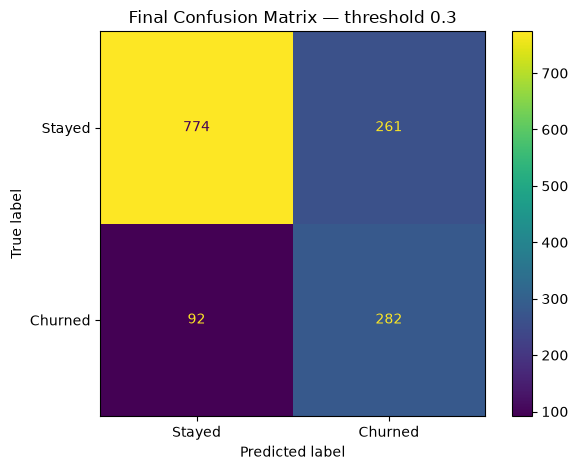

Правильно определённые оставшиеся клиенты (TN): 774
Ложные предупреждения (FP): 261
Пропущенные случаи оттока (FN): 92
Правильно обнаруженные случаи оттока (TP): 282


In [36]:
y_proba_test = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= selected_threshold).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_test),
    "Precision": precision_score(y_test, y_pred_test, zero_division=0),
    "Recall": recall_score(y_test, y_pred_test, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_test, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba_test),
}
final_results_df = pd.DataFrame([final_metrics], index=["Logistic Regression, threshold=0.3"])
display(final_results_df.round(4))

cm_final = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
display_final = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Stayed", "Churned"],
)
display_final.plot(values_format="d")
plt.title(f"Final Confusion Matrix — threshold {selected_threshold}")
plt.tight_layout()
plt.show()

print("Правильно определённые оставшиеся клиенты (TN):", cm_final[0, 0])
print("Ложные предупреждения (FP):", cm_final[0, 1])
print("Пропущенные случаи оттока (FN):", cm_final[1, 0])
print("Правильно обнаруженные случаи оттока (TP):", cm_final[1, 1])

Интерпретация итоговой оценки
- Recall показывает долю реально ушедших клиентов, которых модель обнаружила. При выборе порога 0,3 мы сознательно отдаём приоритет этой метрике.
- Precision показывает, какая доля клиентов, отмеченных моделью как склонные к уходу, действительно ушла. Снижение порога обычно уменьшает Precision и увеличивает количество ложных предупреждений.
- ROC-AUC оценивает способность ранжировать ушедших клиентов выше оставшихся по вероятности оттока и не зависит от выбранного порога.
- При практическом применении порог следует выбирать с учётом стоимости удерживающей кампании, ценности клиента и потерь от ухода.

## 6. Model Export
Сохраняем полный конвейер, включающий предобработку и модель, а также выбранный порог классификации. Артефакты сохраняются в папку models/ в корне проекта. Загружать joblib-файлы следует только из доверенных источников.

In [37]:
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "churn_pipeline.joblib"
threshold_path = models_dir / "selected_threshold.txt"

joblib.dump(final_pipeline, model_path)
threshold_path.write_text(str(selected_threshold), encoding="utf-8")

print("Модель сохранена:", model_path)
print("Порог сохранён:", threshold_path)

Модель сохранена: D:\All projects\PycharmProjects\customer-churn-prediction\models\churn_pipeline.joblib
Порог сохранён: D:\All projects\PycharmProjects\customer-churn-prediction\models\selected_threshold.txt


### 6.1. Verifying the Saved Artifacts
Загружаем модель и порог обратно и проверяем, что предсказания после загрузки совпадают с предсказаниями до сохранения. Для проверки используем ту же тестовую выборку; это проверка сохранения, а не дополнительный подбор модели.

In [38]:
loaded_pipeline = joblib.load(model_path)
loaded_threshold = float(threshold_path.read_text(encoding="utf-8").strip())
loaded_probabilities = loaded_pipeline.predict_proba(X_test)[:, 1]
loaded_predictions = (loaded_probabilities >= loaded_threshold).astype(int)

print("Порог совпадает:", loaded_threshold == selected_threshold)
print("Вероятности совпадают:", np.allclose(loaded_probabilities, y_proba_test))
print("Классы совпадают:", np.array_equal(loaded_predictions, y_pred_test))

Порог совпадает: True
Вероятности совпадают: True
Классы совпадают: True


## 7. Conclusions

### 7.1. Main Findings
Исследовательский анализ показал, что доля оттока в датасете различается между группами клиентов. Наиболее заметная наблюдаемая связь обнаружена для типа договора: отток чаще встречается среди клиентов с помесячным договором. Также в данных доля оттока в целом выше при небольшом сроке обслуживания. Эти закономерности не следует трактовать как доказательство причинности.

### 7.2. Model Evaluation
В проекте сравниваются DummyClassifier, Logistic Regression и Random Forest. Базовая модель демонстрирует, почему одной Accuracy недостаточно: предсказывая только наиболее частый класс, она не обнаруживает отток. Логистическая регрессия используется как итоговая модель-кандидат; порог 0,3 выбран с приоритетом Recall. Численные результаты итоговой оценки приведены в таблице и матрице ошибок выше.

### 7.3. Limitations
- Выбор модели и порога основан на одной валидационной выборке; для более устойчивой оценки можно использовать кросс-валидацию.
- В проекте не проводился систематический подбор гиперпараметров.
- Метрики классификации не учитывают стоимость удерживающих предложений и потенциальную ценность клиента.
- Связи, найденные при EDA, не доказывают причинно-следственные зависимости.

### 7.4. Future Improvements
В дальнейшем можно сравнить модели с кросс-валидацией, провести подбор гиперпараметров, исследовать важность признаков и калибровку вероятностей, а также выбрать порог на основе ожидаемой экономической выгоды от удержания клиентов.